# 📊 Module 2: MovieLens Dataset Exploration & EDA
**Movie Recommendation System Using Machine Learning**

---

### 🎯 Objectives
1. Understand the structure and schema of the **MovieLens Latest Small** dataset.
2. Load and inspect `movies.csv`, `ratings.csv`, `tags.csv`, and `links.csv` using Pandas.
3. Compute statistical summaries and understand **Matrix Sparsity**.
4. Visualize rating distributions, user activity patterns, and movie popularity curves.
5. Practice beginner exercises to reinforce your learning.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean aesthetic styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Environment ready!")


Environment ready!


## 1. Loading the Dataset
We load the raw CSV files stored in the `dataset/` directory.
- `movies.csv`: Maps each `movieId` to its `title` and pipe-separated `genres`.
- `ratings.csv`: Contains historical user interactions `(userId, movieId, rating, timestamp)`.
- `tags.csv`: Free-form user tags applied to movies.
- `links.csv`: Identifiers linking to IMDb and TMDb.


In [2]:
data_dir = "../dataset"

movies_df = pd.read_csv(os.path.join(data_dir, "movies.csv"))
ratings_df = pd.read_csv(os.path.join(data_dir, "ratings.csv"))
tags_df = pd.read_csv(os.path.join(data_dir, "tags.csv"))
links_df = pd.read_csv(os.path.join(data_dir, "links.csv"))

print(f"Movies Shape:  {movies_df.shape}")
print(f"Ratings Shape: {ratings_df.shape}")
print(f"Tags Shape:    {tags_df.shape}")
print(f"Links Shape:   {links_df.shape}")


Movies Shape:  (9742, 3)
Ratings Shape: (100836, 4)
Tags Shape:    (3683, 4)
Links Shape:   (9742, 3)


## 2. Inspecting First Records and Data Types

In [3]:
print("--- MOVIES HEAD ---")
display(movies_df.head(5))

print("\n--- RATINGS HEAD ---")
display(ratings_df.head(5))


--- MOVIES HEAD ---


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



--- RATINGS HEAD ---


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [4]:
print("--- MOVIES INFO ---")
movies_df.info()

print("\n--- RATINGS INFO ---")
ratings_df.info()


--- MOVIES INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB

--- RATINGS INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


## 3. Statistical Summaries & Catalog Sparsity

### What is Matrix Sparsity?
In collaborative filtering, users only rate a tiny fraction of available movies.
$$\text{Sparsity (\%)} = \left(1 - \frac{\text{Total Observed Ratings}}{\text{Unique Users} \times \text{Unique Movies}}\right) \times 100$$


In [5]:
num_users = ratings_df["userId"].nunique()
num_movies = movies_df["movieId"].nunique()
num_ratings = len(ratings_df)

total_possible = num_users * num_movies
sparsity = (1.0 - (num_ratings / total_possible)) * 100.0

print(f"Unique Users:           {num_users:,}")
print(f"Unique Movies:          {num_movies:,}")
print(f"Total Observed Ratings: {num_ratings:,}")
print(f"Total Possible Cells:   {total_possible:,}")
print(f"Matrix Sparsity:        {sparsity:.2f}%")
print(f"\nRating Scale: min={ratings_df['rating'].min()}, max={ratings_df['rating'].max()}, mean={ratings_df['rating'].mean():.2f}")


Unique Users:           610
Unique Movies:          9,742
Total Observed Ratings: 100,836
Total Possible Cells:   5,942,620
Matrix Sparsity:        98.30%

Rating Scale: min=0.5, max=5.0, mean=3.50


## 4. Visualizing Rating Distributions
Let's see how users distribute their scores (0.5 to 5.0).


C:\Users\shivania\AppData\Local\Temp\ipykernel_25544\714601535.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, palette="Blues_d")


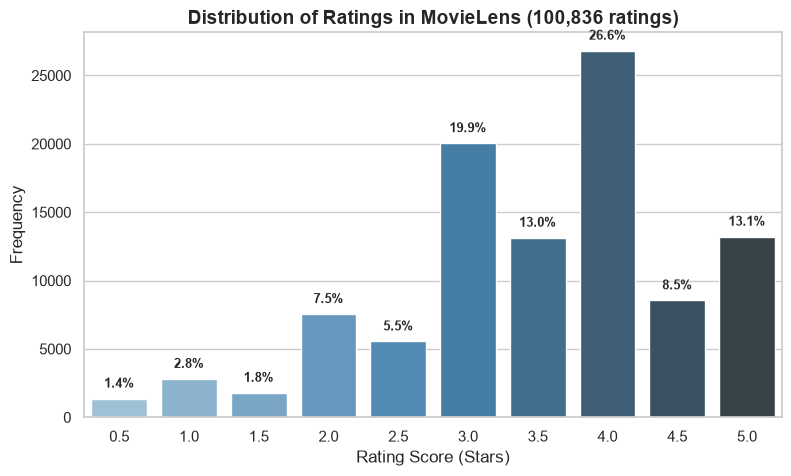

In [6]:
rating_counts = ratings_df["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, palette="Blues_d")
plt.title("Distribution of Ratings in MovieLens (100,836 ratings)", fontsize=14, fontweight="bold")
plt.xlabel("Rating Score (Stars)")
plt.ylabel("Frequency")

for p in ax.patches:
    h = p.get_height()
    pct = (h / num_ratings) * 100
    ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, h + 800), ha="center", fontsize=9, fontweight="bold")

plt.show()


## 5. Identifying the Most-Rated Movies

C:\Users\shivania\AppData\Local\Temp\ipykernel_25544\358096016.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_movies, y="title", x="rating_count", palette="viridis")


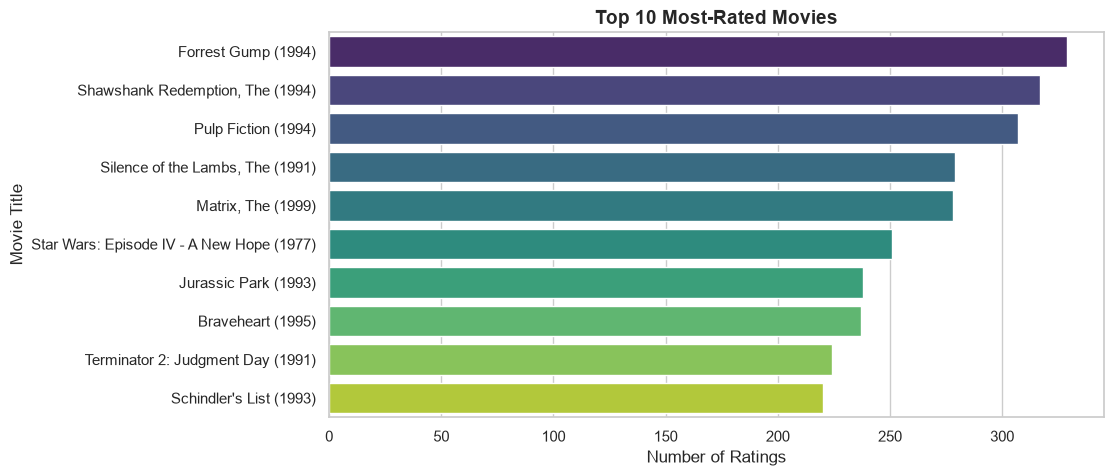

In [7]:
top_movies = ratings_df["movieId"].value_counts().head(10).reset_index()
top_movies.columns = ["movieId", "rating_count"]
top_movies = top_movies.merge(movies_df, on="movieId")

plt.figure(figsize=(10, 5))
sns.barplot(data=top_movies, y="title", x="rating_count", palette="viridis")
plt.title("Top 10 Most-Rated Movies", fontsize=14, fontweight="bold")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie Title")
plt.show()


## 6. Beginner Exercises & Common Pitfalls

### 📝 Exercises
1. Find the user who has rated the largest number of movies. How many ratings did they submit?
2. Calculate the average rating for movies in the `Animation` genre versus `Action` genre.
3. Why are half-star ratings (e.g. 0.5, 1.5, 2.5) less common than integer ratings (e.g. 3.0, 4.0)?

### ⚠️ Common Errors & Fixes
- **Error:** `KeyError: 'title'` when merging `ratings_df` and `movies_df`.
  - **Fix:** Ensure merge is done using `on='movieId'` and that column names match casing.
- **Error:** Memory crash when computing `ratings_df.pivot(...)` on massive datasets.
  - **Fix:** Never pivot uncompressed millions of entries into dense matrices without sparse representation!
